# Practical Machine Learning — Day 01 Lab
## Data Preparation, Cleaning and Transformation Using Python
**CDAC PGCP-AI · Practical Machine Learning · 23 October 2026 · Duration: 3 hours**

## Section 0 — Welcome and Instructions

### 🎯 Learning objectives
By the end of this lab you will be able to:
1. Load and explore a raw dataset and understand its data types.
2. Find missing values, duplicates and inconsistent values.
3. Clean numerical and categorical columns using documented business rules.
4. Perform basic transformations (encoding, normalisation, standardisation).
5. Validate your results and export a cleaned dataset.

### ⏱️ Estimated time (180 minutes)
| Stage | Exercises | Time |
|---|---|---|
| A — Explore the dataset | A1 – A9 | 60 min |
| B — Clean the dataset | B1 – B9 | 60 min |
| C — Transform and validate | C1 – C8 | 60 min |

### 📁 Files you need (keep them in the same folder as this notebook)
- `06_customer_data_dirty.csv` — the raw dataset (**never edit or overwrite it**)
- `07_Data_Dictionary.xlsx` — column meanings and the **business rules** you must apply

### ✍️ How to complete the blank code
- A blank looks like `____`. Replace it with the missing method, value or expression.
- Every blank is labelled `# TODO (ID)` — e.g. `A1-1` is the first blank of Exercise A1.
- Until a blank is completed, the cell will **fail on purpose** (usually with `AttributeError`, `NameError` or `SyntaxError`). That is normal.
- Some tasks are *debugging* tasks (find and fix the bug) or *write-it-yourself* tasks — they are marked **Level 4** and **Level 5**.

| Level | What you do |
|---|---|
| 1 | Complete a pandas method |
| 2 | Complete a statement, argument or expression |
| 3 | Choose the correct preprocessing technique |
| 4 | Debug a short, incorrect snippet |
| 5 | Write a small validation check on your own |

### ▶️ How to run cells
Click a cell and press **Shift + Enter**. **Run the cells in order, top to bottom.** If something behaves strangely, use *Kernel → Restart & Run All* (Colab: *Runtime → Restart and run all*) after finishing your blanks.

### 📤 What to submit
1. This completed notebook (`.ipynb`)
2. `customer_data_cleaned.csv` (created in Exercise C7)
3. The before-and-after quality summary table (created in Exercise C6)
4. Your short written conclusions (Section 17)

### ⚠️ Golden rules
- Work on a **copy** of the data (`clean_df`), never on the raw `df`.
- **Do not delete rows just because they look odd.** Decide *why* first; flag what you cannot resolve.
- Every cleaning decision must be explainable: *what was wrong, what did I do, why?*
- No machine-learning model is trained today. Day 01 is about getting the data ready.

---
# STAGE A — Explore the Dataset (60 min)
## Section 1 — Import Libraries and Load Data

### Exercise A1 — Load the CSV

**Level 1** &nbsp;|&nbsp; **Task:** Read `06_customer_data_dirty.csv` into a DataFrame called `df`.

**You should see:** A message *Loaded: 06_customer_data_dirty.csv* (no error).

<details><summary>💡 Hint (try first without it)</summary>

Pandas has a family of `read_...` functions, one per file type. Which one reads comma-separated values?

</details>

In [364]:
# ===== Exercise A1 =====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DATA_FILE = "06_customer_data_dirty.csv"

# TODO (A1-1): complete the pandas function that reads a CSV file
df = pd.read_csv(DATA_FILE)
print("Loaded:", DATA_FILE)

Loaded: 06_customer_data_dirty.csv


✏️ **Your answer to A1:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise A2 — Display the first 10 records

**Level 1** &nbsp;|&nbsp; **Task:** Show the first **10** rows of `df`.

**You should see:** A table with 10 rows and 9 columns. Look closely — can you already spot anything odd?

<details><summary>💡 Hint (try first without it)</summary>

The method name is the 'top of the table' word. It takes the number of rows as an argument.

</details>

In [365]:
# ===== Exercise A2 =====
# TODO (A2-1): show the first 10 records
df.head(10)

,customer_id,age,annual_income_inr,city,account_type,preferred_channel,signup_date,transactions_last_30d,avg_transaction_amount_inr
0,CUST0001,32,768000,Mumbai,Savings,Mobile,2024-08-21,9.0,6664.30
1,CUST0002,40,INR 770000,Mumbai,Current,Mobile,2019-06-24,21.0,2508.71
2,CUST0003,21,NaN,Bengaluru,Basic,Mobile,2018-08-27,16.0,7929.87
3,CUST0004,999,585500,Ahmedabad,Savings,Web,2022-12-14,16.0,3039.58
4,CUST0005,54,570000,Delhi,Premium,branch,2022-02-03,20.0,5056.26
5,CUST0006,34,306500,Delhi,Savings,Mobile,2020-02-18,14.0,4975.35
6,CUST0007,32 yrs,862000,Mumbai,Savings,Branch,17/02/2024,13.0,1332.89
7,CUST0008,58,591500,Delhi,Premium,Mobile,2019-02-12,19.0,1369.91
8,CUST0009,33,3258000,New Delhi,Premium,Web,2023-08-10,18.0,3732.06
9,CUST0010,43,833500,Mumbai,Savings,Mobile,2025-07-19,12.0,949.32


✏️ **Your answer to A2:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 2 — Explore the Dataset

### Exercise A3 — Rows and columns

**Level 1** &nbsp;|&nbsp; **Task:** Find how many rows and columns `df` has.

**You should see:** `Rows: <number>` and `Columns: 9`, followed by the list of column names.

<details><summary>💡 Hint (try first without it)</summary>

It is an *attribute* (no brackets) that returns a pair: (number of rows, number of columns).

</details>

In [366]:
# ===== Exercise A3 =====
# TODO (A3-1): complete the attribute that returns (rows, columns)
rows, columns = df.shape

print("Rows:", rows)
print("Columns:", columns)
print("Column names:", list(df.columns))

Rows: 460
Columns: 9
Column names: ['customer_id', 'age', 'annual_income_inr', 'city', 'account_type', 'preferred_channel', 'signup_date', 'transactions_last_30d', 'avg_transaction_amount_inr']


✏️ **Your answer to A3:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise A4 — Understand the data types

**Level 1** &nbsp;|&nbsp; **Task:** Display the data type and the number of non-null values of every column.

**You should see:** A summary listing 9 columns. **Look at the Dtype column:** which columns that *should* be numbers are not?

<details><summary>💡 Hint (try first without it)</summary>

The method name is a synonym for 'information'.

</details>

**🤔 Reflect (A4):** Which numeric-looking columns are stored as text, and what do you think causes this?

In [367]:
# ===== Exercise A4 =====
# TODO (A4-1): display column dtypes, non-null counts and memory usage
df.dtypes

customer_id                    object
age                            object
annual_income_inr              object
city                           object
account_type                   object
preferred_channel              object
signup_date                    object
transactions_last_30d         float64
avg_transaction_amount_inr    float64
dtype: object

✏️ **Your answer to A4:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise A5 — Descriptive statistics

**Level 1** &nbsp;|&nbsp; **Task:** Run the summary-statistics cells and interpret them.

**You should see:** A table of count / mean / min / max for numeric columns, then one for text columns. **Notice which columns are missing from the first table.**

<details><summary>💡 Hint (try first without it)</summary>

No blank here — just run the cells. Compare *min* and *max* with what you would expect from real customers.

</details>

**🤔 Reflect (A5):** Why do only two columns appear in `df.describe()`? What would a numeric summary of `annual_income_inr` tell us if it were converted?

In [368]:
# ===== Exercise A5 =====
# Numeric summary (only columns pandas already treats as numbers)
display(df.describe())

# Summary of ALL columns, transposed so it is easier to read
display(df.describe(include="all").T)

,transactions_last_30d,avg_transaction_amount_inr
count,439.000000,4.350000e+02
mean,19.897494,1.287812e+04
std,53.994681,8.863527e+04
min,-12.000000,-9.999000e+03
25%,11.000000,2.116905e+03
50%,15.000000,3.338330e+03
75%,20.000000,5.213915e+03
max,999.000000,1.250000e+06


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,460,440,CUST0167,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,438,63,21,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income_inr,429,398,795000,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,444,40,Mumbai,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_type,450,17,Savings,227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
preferred_channel,442,15,Mobile,206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,448,408,2020-09-30,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transactions_last_30d,439.0,NaN,NaN,NaN,19.897494,53.994681,-12.0,11.0,15.0,20.0,999.0
avg_transaction_amount_inr,435.0,NaN,NaN,NaN,12878.124138,88635.27145,-9999.0,2116.905,3338.33,5213.915,1250000.0


✏️ **Your answer to A5:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 3 — Missing Values

### Exercise A6 — Count missing values

**Level 1** &nbsp;|&nbsp; **Task:** Count the missing values in every column and express them as a percentage of all rows.

**You should see:** A table with one row per column: `missing_count` and `missing_percent`, sorted from most to least missing.

<details><summary>💡 Hint (try first without it)</summary>

Pandas has two equivalent methods that return True where a value is missing (one sounds like 'is null', the other like 'is NA'). `True` counts as 1 when you `.sum()`.

</details>

**🤔 Reflect (A6):** Which column has the highest number of missing values? Is the amount large enough to worry about?

In [369]:
# ===== Exercise A6 =====
# TODO (A6-1): True where a value is missing, then add them up per column
missing_values = df.isnull().sum()

missing_pct = (missing_values / len(df) * 100).round(2)
missing_report = pd.DataFrame({"missing_count": missing_values, "missing_percent": missing_pct})
missing_report.sort_values("missing_count", ascending=False)

,missing_count,missing_percent
annual_income_inr,31,6.74
avg_transaction_amount_inr,25,5.43
age,22,4.78
transactions_last_30d,21,4.57
preferred_channel,18,3.91
city,16,3.48
signup_date,12,2.61
account_type,10,2.17
customer_id,0,0.00


✏️ **Your answer to A6:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 4 — Duplicate Records

### Exercise A7 — Exact duplicates and repeated customer IDs

**Level 2** &nbsp;|&nbsp; **Task:** (a) Count rows that are **exact copies** of an earlier row. (b) Find rows whose `customer_id` appears more than once, then separate *exact copies* from *conflicting* records.

**You should see:** Two counts, then a table of repeated-ID rows. Some IDs repeat with identical values; a few repeat with **different** values.

<details><summary>💡 Hint (try first without it)</summary>

(a) The method name is a synonym for 'repeated'. (b) `value_counts()` returns how many times each ID appears — which count means the ID is repeated?

</details>

**🤔 Reflect (A7):** Why would it be dangerous to remove every row whose customer_id repeats?

In [370]:
# ===== Exercise A7 =====
# (a) TODO (A7-1): count rows that are exact copies of an earlier row
exact_duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", exact_duplicate_count)

Exact duplicate rows: 12


In [371]:
# (b) Repeated customer IDs: how many times does each ID appear?
id_counts = df["customer_id"].value_counts()
print(id_counts)

customer_id
CUST0167    2
CUST0205    2
CUST0035    2
CUST0252    2
CUST0411    2
           ..
CUST0020    1
CUST0021    1
CUST0022    1
CUST0023    1
CUST0423    1
Name: count, Length: 440, dtype: int64


In [372]:
# TODO (A7-2): keep only the IDs that appear MORE than this many times (what count means "repeated"?)
repeated_ids = id_counts[id_counts > 1].index
print(list(repeated_ids))

['CUST0167', 'CUST0205', 'CUST0035', 'CUST0252', 'CUST0411', 'CUST0195', 'CUST0074', 'CUST0439', 'CUST0096', 'CUST0134', 'CUST0203', 'CUST0043', 'CUST0347', 'CUST0416', 'CUST0312', 'CUST0100', 'CUST0239', 'CUST0337', 'CUST0315', 'CUST0396']


In [373]:
repeated_id_rows = df.set_index("customer_id")
repeated_id_rows=repeated_id_rows.loc[repeated_ids]
repeated_id_rows=repeated_id_rows.reset_index()
repeated_id_rows=repeated_id_rows.sort_values("customer_id")
print(repeated_id_rows)

   customer_id age annual_income_inr       city account_type  \
4     CUST0035  53            664000     Jaipur      Savings   
5     CUST0035  53            664000     Jaipur      Savings   
23    CUST0043  40           1435500  Bengaluru      Savings   
22    CUST0043  40           1148500  Bengaluru      Savings   
13    CUST0074  51           3484000  Ahmedabad      Savings   
12    CUST0074  51           2787000  Ahmedabad      Savings   
17    CUST0096  40            593000       Pune      Savings   
16    CUST0096  40            593000       Pune      Savings   
31    CUST0100  29            757500    Lucknow      Premium   
30    CUST0100  29            757500    Lucknow      Premium   
19    CUST0134  54            853000     Mumbai      Current   
18    CUST0134  54            853000     Mumbai      Current   
0     CUST0167  34           3234000     Mumbai      Savings   
1     CUST0167  34           2310000     Mumbai      Savings   
11    CUST0195  36            685000    

In [374]:
print("Rows whose customer_id appears more than once:", len(repeated_id_rows))

Rows whose customer_id appears more than once: 40


In [375]:
# Which repeated IDs are exact copies, and which have CONFLICTING values? (provided)
# For every ID count the distinct values in each column; if ANY column has 2+ distinct values the rows disagree.
distinct_per_id = df.groupby("customer_id").nunique(dropna=False)
print(distinct_per_id)

             age  annual_income_inr  city  account_type  preferred_channel  \
customer_id                                                                  
 CUST0166      1                  1     1             1                  1   
 CUST0324      1                  1     1             1                  1   
CUST0001       1                  1     1             1                  1   
CUST0002       1                  1     1             1                  1   
CUST0003       1                  1     1             1                  1   
...          ...                ...   ...           ...                ...   
CUST0439       1                  2     1             2                  1   
CUST0440       1                  1     1             1                  1   
cust0143       1                  1     1             1                  1   
cust0352       1                  1     1             1                  1   
cust0409       1                  1     1             1         

In [376]:
conflicting_ids = sorted(distinct_per_id[(distinct_per_id > 1).any(axis=1)].index)
print(conflicting_ids)

['CUST0043', 'CUST0074', 'CUST0167', 'CUST0205', 'CUST0252', 'CUST0337', 'CUST0347', 'CUST0439']


In [377]:
exact_copy_ids = set(repeated_id_rows["customer_id"]) - set(conflicting_ids)
print("IDs repeated as exact copies :", len(exact_copy_ids))
print("IDs repeated with CONFLICTING data:", len(conflicting_ids))

IDs repeated as exact copies : 12
IDs repeated with CONFLICTING data: 8


In [378]:
df.set_index("customer_id").loc[conflicting_ids].head(10)

,age,annual_income_inr,city,account_type,preferred_channel,signup_date,transactions_last_30d,avg_transaction_amount_inr
customer_id,,,,,,,,
CUST0043,40,1148500,Bengaluru,Savings,Mobile,2025-01-29,13.0,2006.84
CUST0043,40,1435500,Bengaluru,Savings,Mobile,2025-01-29,18.0,3210.94
CUST0074,51,2787000,Ahmedabad,Savings,Web,2025-04-30,14.0,5062.54
CUST0074,51,3484000,Ahmedabad,Savings,Web,2025-04-30,23.0,8100.06
CUST0167,34,3234000,Mumbai,Savings,Mobile,2018-07-02,27.0,3335.17
CUST0167,34,2310000,Mumbai,Savings,Mobile,2018-07-02,18.0,4168.96
CUST0205,51,1534000,Ahmedabad,Premium,Web,2019-05-02,20.0,1484.33
CUST0205,51,1074000,Ahmedabad,Savings,Web,2019-05-02,29.0,1929.63
CUST0252,39,831500,Mumbai,Current,Web,2020-01-20,18.0,5684.90


✏️ **Your answer to A7:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 5 — Suspicious Values, Inconsistent Categories and Visual Checks

### Exercise A8 — Spot suspicious values and inconsistent categories

**Level 2** &nbsp;|&nbsp; **Task:** Run the inspection cells and **write down every problem you can find** (use the Issue Log below).

**You should see:** Value counts showing spelling variants, blanks and unexpected categories; and numeric checks showing ages outside 18–100 and negative values.

<details><summary>💡 Hint (try first without it)</summary>

Compare what you see with the rules in `07_Data_Dictionary.xlsx` (sheet *Business Rules*). A value is **invalid** if it breaks a hard rule, **suspicious** if it is possible but unusual.

</details>

**🤔 Reflect (A8):** When should a suspicious value be flagged instead of automatically replaced?

In [379]:
# ===== Exercise A8 =====
# (a) Inconsistent categories
for col in ["city", "account_type", "preferred_channel"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- city ---
city
Mumbai          67
Delhi           64
Bengaluru       51
Pune            43
Chennai         33
Kolkata         27
Ahmedabad       25
Hyderabad       24
Jaipur          19
NaN             16
Lucknow         13
Bangalore        8
Bombay           8
New Delhi        5
 Mumbai          4
HYDERABAD        4
PUNE             4
Madras           4
Calcutta         3
delhi            3
mumbai           3
AHMEDABAD        3
hyderabad        2
Chennai          2
LUCKNOW          2
Delhi            2
 Pune            2
Jaipur           2
Hyderabad        2
Delhi            2
kolkata          2
ahmedabad        2
 Jaipur          1
lucknow          1
Hyderabad        1
 Hyderabad       1
pune             1
Ahmedabad        1
Pune             1
Mumbai           1
JAIPUR           1
Name: count, dtype: int64

--- account_type ---
account_type
Savings     227
Current     102
Premium      70
NaN          10
Savings       6
SAVINGS       6
Gold          5
 Savings      5
savings       

In [380]:
# ===== Exercise A8 =====
# (a) Inconsistent categories
for col in ["city", "account_type", "preferred_channel"]:
    print(f"--- {col} ---")
    print(df[col].unique())
    print()

--- city ---
[' Mumbai  ' 'Mumbai' 'Bengaluru' 'Ahmedabad' 'Delhi' 'New Delhi'
 ' Jaipur  ' 'Chennai' 'Pune' 'Hyderabad' 'Jaipur' 'Kolkata' 'PUNE'
 'Bombay' 'mumbai' 'HYDERABAD' 'Chennai ' 'LUCKNOW' 'AHMEDABAD' 'Lucknow'
 'Hyderabad  ' 'lucknow' 'delhi' 'Jaipur  ' ' Pune  ' nan 'kolkata'
 'Hyderabad ' 'Calcutta' 'Bangalore' 'Delhi  ' 'Delhi ' 'Madras'
 ' Hyderabad  ' 'pune' 'Pune ' 'Ahmedabad ' 'hyderabad' 'Mumbai  '
 'JAIPUR' 'ahmedabad']

--- account_type ---
['Savings' 'Current' 'Basic' 'Premium' 'PREMIUM' 'current' 'SAVINGS'
 'Savings ' 'Gold' ' Savings' nan 'premium' 'savings' 'Student' 'Premium '
 'CURRENT' ' Current' ' Premium']

--- preferred_channel ---
['Mobile' 'Web' 'branch' 'Branch' nan ' Web ' 'Kiosk' ' Mobile ' 'web'
 'mobile' 'MOBILE' 'Phone' 'ATM' 'BRANCH' 'WEB' ' Branch ']



In [381]:
# --- city ---
# [' Mumbai  ' 'Mumbai' 'Bengaluru' 'Ahmedabad' 'Delhi' 'New Delhi'
#  ' Jaipur  ' 'Chennai' 'Pune' 'Hyderabad' 'Jaipur' 'Kolkata' 'PUNE'
#  'Bombay' 'mumbai' 'HYDERABAD' 'Chennai ' 'LUCKNOW' 'AHMEDABAD' 'Lucknow'
#  'Hyderabad  ' 'lucknow' 'delhi' 'Jaipur  ' ' Pune  ' nan 'kolkata'
#  'Hyderabad ' 'Calcutta' 'Bangalore' 'Delhi  ' 'Delhi ' 'Madras'
#  ' Hyderabad  ' 'pune' 'Pune ' 'Ahmedabad ' 'hyderabad' 'Mumbai  '
#  'JAIPUR' 'ahmedabad']

# --- account_type ---
# ['Savings' 'Current' 'Basic' 'Premium' 'PREMIUM' 'current' 'SAVINGS'
#  'Savings ' 'Gold' ' Savings' nan 'premium' 'savings' 'Student' 'Premium '
#  'CURRENT' ' Current' ' Premium']

# --- preferred_channel ---
# ['Mobile' 'Web' 'branch' 'Branch' nan ' Web ' 'Kiosk' ' Mobile ' 'web'
#  'mobile' 'MOBILE' 'Phone' 'ATM' 'BRANCH' 'WEB' ' Branch ']

In [382]:
# (b) Suspicious numbers. We convert a COPY just for inspection; df itself stays raw.
age_check = df["age"].astype(str).str.extract(r"(-?\d+)", expand=False).astype(float)   # grab the digits (keep a minus sign)
print("Ages written with letters (e.g. '34 yrs'):", df["age"].str.contains("[A-Za-z]", na=False).sum())

Ages written with letters (e.g. '34 yrs'): 6


In [383]:
print(age_check.describe().round(1))
print("\nAges outside the valid range 18-100:")

count    438.0
mean      40.7
std       48.9
min       -5.0
25%       30.0
50%       37.0
75%       44.0
max      999.0
Name: age, dtype: float64

Ages outside the valid range 18-100:


In [384]:
display(df.loc[(age_check < 18) | (age_check > 100)])

,customer_id,age,annual_income_inr,city,account_type,preferred_channel,signup_date,transactions_last_30d,avg_transaction_amount_inr
3,CUST0004,999,585500,Ahmedabad,Savings,Web,2022-12-14,16.0,3039.58
23,CUST0024,17,672000,PUNE,Savings,Mobile,2023-11-25,10.0,3058.77
103,CUST0101,7,"5,71,500",Delhi,Current,web,2021-02-24,24.0,3984.53
145,CUST0141,16,516500,Pune,savings,Phone,2023-11-15,18.0,1465.70
170,CUST0165,150,1030500,Delhi,Current,Web,2023-01-21,22.0,4455.05
191,CUST0185,0,2002000,Mumbai,Savings,NaN,17-Sep-2026,-5.0,289.06
197,CUST0190,250,827500,Kolkata,Current,Web,2022-10-10,27.0,6483.20
253,CUST0244,12,624000,Bangalore,Savings,Mobile,2023-10-03,13.0,3763.39
378,CUST0365,-5,952500,Ahmedabad,NaN,Web,2022-10-28,21.0,1978.32


In [385]:
print(age_check)

0       32.0
1       40.0
2       21.0
3      999.0
4       54.0
       ...  
455     39.0
456     40.0
457     36.0
458     47.0
459     29.0
Name: age, Length: 460, dtype: float64


In [386]:
display(df.loc[~age_check.between(18,100) & age_check.notna()])

,customer_id,age,annual_income_inr,city,account_type,preferred_channel,signup_date,transactions_last_30d,avg_transaction_amount_inr
3,CUST0004,999,585500,Ahmedabad,Savings,Web,2022-12-14,16.0,3039.58
23,CUST0024,17,672000,PUNE,Savings,Mobile,2023-11-25,10.0,3058.77
103,CUST0101,7,"5,71,500",Delhi,Current,web,2021-02-24,24.0,3984.53
145,CUST0141,16,516500,Pune,savings,Phone,2023-11-15,18.0,1465.70
170,CUST0165,150,1030500,Delhi,Current,Web,2023-01-21,22.0,4455.05
191,CUST0185,0,2002000,Mumbai,Savings,NaN,17-Sep-2026,-5.0,289.06
197,CUST0190,250,827500,Kolkata,Current,Web,2022-10-10,27.0,6483.20
253,CUST0244,12,624000,Bangalore,Savings,Mobile,2023-10-03,13.0,3763.39
378,CUST0365,-5,952500,Ahmedabad,NaN,Web,2022-10-28,21.0,1978.32


In [387]:
symbols_in_income = df["annual_income_inr"].str.contains(r"[^0-9\-]", na=False) #-----> ^ means not in regex
print(symbols_in_income)
print("Income cells containing symbols, commas or letters:", symbols_in_income.sum())

0      False
1       True
2      False
3      False
4      False
       ...  
455    False
456    False
457    False
458    False
459    False
Name: annual_income_inr, Length: 460, dtype: bool
Income cells containing symbols, commas or letters: 63


In [388]:
display(df.loc[symbols_in_income, "annual_income_inr"].head(8))


1     INR 770000
21     1,244,000
30     19,16,000
49      ₹1256500
51    ₹24,43,000
67      9,55,000
73     ₹7,00,500
74      7,38,500
Name: annual_income_inr, dtype: object

In [389]:
print("Negative transaction counts :", (df["transactions_last_30d"] < 0).sum())
print("Negative average amounts    :", (df["avg_transaction_amount_inr"] < 0).sum())

Negative transaction counts : 6
Negative average amounts    : 6


#### 📝 Issue Log (edit this table — add rows as you find problems)
| # | Column | Problem found | Example value | Rule it breaks |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |
| 6 | | | | |

✏️ **Your answer to A8:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise A9 — Two exploratory visualisations

**Level 1** &nbsp;|&nbsp; **Task:** Create (1) a histogram of the raw ages and (2) a bar chart of the raw city values.

**You should see:** Two charts side by side. The histogram is stretched by impossible ages; the bar chart shows the same city split into many labels.

<details><summary>💡 Hint (try first without it)</summary>

A histogram method is named after the chart type. It needs the values and `bins=`.

</details>

**🤔 Reflect (A9):** What do the two charts reveal that `describe()` did not make obvious?

In [390]:
import seaborn as sns

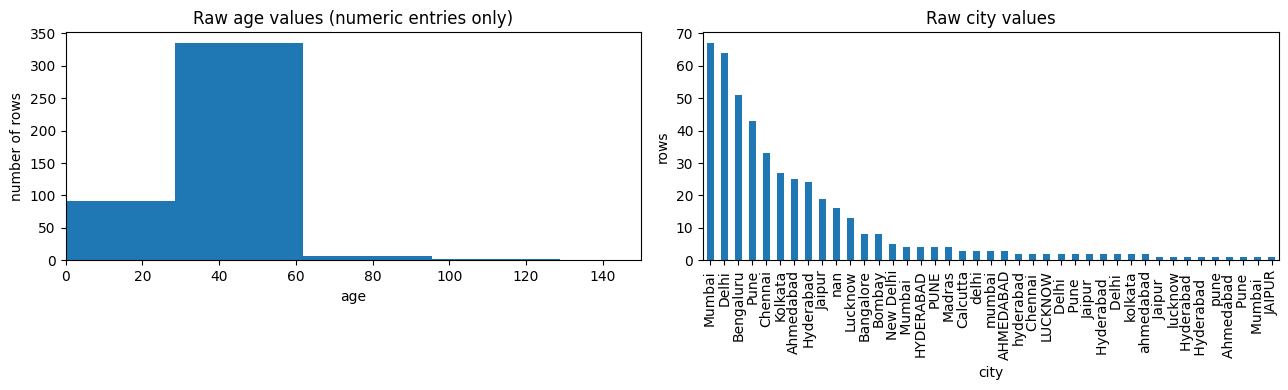

In [391]:
# ===== Exercise A9 =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot 1 - TODO (A9-1): draw a histogram of the numeric ages with 30 bins
axes[0].hist(age_check.dropna(), bins=30)
axes[0].set_title("Raw age values (numeric entries only)")
axes[0].set_xlabel("age")
axes[0].set_xlim(0, 150)
axes[0].set_ylabel("number of rows")

# Plot 2 - provided: raw city labels (note the spelling / capitalisation variants)
df["city"].value_counts(dropna=False).plot(kind="bar", ax=axes[1])
axes[1].set_title("Raw city values")
axes[1].set_ylabel("rows")

plt.tight_layout()
plt.show()

✏️ **Your answer to A9:** *(double-click this cell and type your answer here)*

&nbsp;


---
# STAGE B — Clean the Dataset (60 min)
> **Why this order?** Fix the *format* first (strings, numbers), then deal with *impossible* values, *missing* categories, *duplicates*, and only then **impute** the missing numbers. Imputing before removing duplicates or impossible values would let bad rows influence the median.

## Section 6 — Working Copy and Text Standardisation

### Exercise B1 — Create a working copy

**Level 1** &nbsp;|&nbsp; **Task:** Create `clean_df`, an independent copy of `df`.

**You should see:** A message confirming the copy has the same shape as `df`.

<details><summary>💡 Hint (try first without it)</summary>

A DataFrame method named after exactly what you want to do. `clean_df = df` would NOT make a copy — it would just give the same object a second name.

</details>

In [392]:
# ===== Exercise B1 =====
# TODO (B1-1): create an independent copy of df
clean_df = df.copy()

assert clean_df is not df, "clean_df must be a COPY, not another name for df"
print("Working copy created:", clean_df.shape)

Working copy created: (460, 9)


✏️ **Your answer to B1:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise B2 — Correct inconsistent string formatting

**Level 2** &nbsp;|&nbsp; **Task:** (1) Remove leading/trailing spaces, (2) apply consistent capitalisation, (3) map the documented city aliases to their standard names.

**You should see:** A city list of **10 standard names + NaN** (no `MUMBAI`, no `Bombay`, no padded names).

<details><summary>💡 Hint (try first without it)</summary>

(1) a `.str` method that 'strips' whitespace. (2) a `.str` method that writes Every Word Capitalised. (3) A Series method that *replaces* values using a dictionary — careful: `map()` would turn every city NOT in the dictionary into NaN!

</details>

**🤔 Reflect (B2):** Why do we strip spaces *before* changing the capitalisation and applying the alias dictionary?

In [393]:
# ===== Exercise B2 =====
text_cols = ["customer_id", "city", "account_type", "preferred_channel"]

# (1) TODO (B2-1): remove spaces at the start and end of every text value
for col in text_cols:
    clean_df[col] = clean_df[col].str.strip()

# customer_id: IDs are always upper-case (provided)
clean_df["customer_id"] = clean_df["customer_id"].str.upper()

# (2) TODO (B2-2): consistent capitalisation, e.g. "mumbai" / "MUMBAI" -> "Mumbai"
for col in ["city", "account_type", "preferred_channel"]:
    clean_df[col] = clean_df[col].str.title()

# (3) Documented aliases - see 07_Data_Dictionary.xlsx, sheet "City Aliases"
city_aliases = {"Bombay": "Mumbai", "Bangalore": "Bengaluru", "New Delhi": "Delhi",
                "Madras": "Chennai", "Calcutta": "Kolkata"}
# TODO (B2-3): replace every alias by its standard name; all other cities must stay unchanged
clean_df["city"] = clean_df["city"].replace(city_aliases)

print(clean_df["city"].value_counts(dropna=False))

city
Mumbai       83
Delhi        76
Bengaluru    59
Pune         51
Chennai      39
Hyderabad    34
Kolkata      32
Ahmedabad    31
Jaipur       23
Lucknow      16
NaN          16
Name: count, dtype: int64


✏️ **Your answer to B2:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 7 — Numeric Conversion and Invalid Values

### Exercise B3 — Convert numerical values stored as strings

**Level 2** &nbsp;|&nbsp; **Task:** Complete the helper `to_number()`, then use it to turn `age` and `annual_income_inr` into real numbers. Then **debug** the 'quick fix' below.

**You should see:** `age` and `annual_income_inr` become float columns. `describe()` now shows min/max (including impossible values — we deal with those next).

<details><summary>💡 Hint (try first without it)</summary>

`₹5,40,000`, `INR 540000` and `34 yrs` all become numbers once everything except digits, a decimal point and a minus sign is removed. The final step is a pandas function for converting to numbers; `errors="coerce"` turns impossible conversions into NaN.

</details>

**🤔 Reflect (B3):** Why is `errors="coerce"` safer than leaving the default (`errors="raise"`) here — and what is the danger of coercing blindly?

In [394]:
# ===== Exercise B3 =====
def to_number(series):
    """Turn text such as '₹5,40,000', 'INR 540000' or '34 yrs' into numbers (unreadable text -> NaN)."""
    only_number_chars = series.astype(str).str.replace(r"[^0-9.\-]", "", regex=True)
    # TODO (B3-1): convert the cleaned text to numbers; anything unreadable must become NaN
    return pd.to_numeric(only_number_chars, errors="coerce")


for col in ["age", "annual_income_inr"]:
    clean_df[col] = to_number(clean_df[col])

clean_df[["age", "annual_income_inr"]].describe().round(1)

,age,annual_income_inr
count,438.0,429.0
mean,40.7,1660047.8
std,48.9,9050605.9
min,-5.0,-950000.0
25%,30.0,501000.0
50%,37.0,757500.0
75%,44.0,1160500.0
max,999.0,150000000.0


In [395]:
# ===== Exercise B3-D (Level 4: DEBUG) =====
# A colleague wrote a shorter conversion for income. It silently corrupts the data. Find the bug and fix it.
buggy = df["annual_income_inr"].astype(str).str.replace(r"[^0-9.\-]", "", regex=True)
buggy = pd.to_numeric(buggy, errors="coerce")

negatives_correct = (to_number(df["annual_income_inr"]) < 0).sum()
negatives_buggy = (buggy < 0).sum()
print("Negative incomes (correct conversion):", negatives_correct)
print("Negative incomes (colleague's code)   :", negatives_buggy)
assert negatives_buggy == negatives_correct, "Still wrong - think about which character carries the sign!"

Negative incomes (correct conversion): 6
Negative incomes (colleague's code)   : 6


✏️ **Your answer to B3:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise B4 — Detect invalid and suspicious numerical values

**Level 2** &nbsp;|&nbsp; **Task:** Create **flag columns** from the business rules, count them, and turn *impossible* values into missing values. **Suspicious values are flagged but NOT changed.**

**You should see:** A count per flag column. Afterwards no impossible value remains in the numeric columns, but suspicious values are still there and still flagged.

<details><summary>💡 Hint (try first without it)</summary>

Open `07_Data_Dictionary.xlsx` → sheet *Business Rules*. Income must be positive; the 'suspiciously high income' limit is written there in rupees.

</details>

**🤔 Reflect (B4):** What is the difference between an *invalid* and a *suspicious* value, and why do we treat them differently?

In [396]:
q1 = clean_df["annual_income_inr"].quantile(0.25)
q1

np.float64(501000.0)

In [397]:
q3 = clean_df["annual_income_inr"].quantile(0.75)
q3

np.float64(1160500.0)

In [398]:
IQR = q3-q1
IQR

np.float64(659500.0)

In [399]:
uf = q3+(1.5*IQR)
uf

np.float64(2149750.0)

In [400]:
# ===== Exercise B4 =====
# Business rules come from 07_Data_Dictionary.xlsx -> sheet "Business Rules"
clean_df["age_invalid"] = (clean_df["age"] < 18) | (clean_df["age"] > 100)
clean_df["age_suspicious"] = clean_df["age"].between(90, 100)

In [401]:
# TODO (B4-1): income must be a positive number -> flag values that are zero or below
clean_df["income_invalid"] = clean_df["annual_income_inr"] <= 0
# TODO (B4-2): copy the "suspiciously high income" limit (in rupees) from the Business Rules sheet
clean_df["income_suspicious"] = clean_df["annual_income_inr"] > 10000000

In [402]:
clean_df["txn_invalid"] = clean_df["transactions_last_30d"] < 0
clean_df["txn_suspicious"] = clean_df["transactions_last_30d"] > 100
clean_df["avg_amt_invalid"] = clean_df["avg_transaction_amount_inr"] < 0
clean_df["avg_amt_suspicious"] = clean_df["avg_transaction_amount_inr"] > 200_000

In [403]:
flag_cols = [c for c in clean_df.columns if c.endswith("_invalid") or c.endswith("_suspicious")]
flag_counts_raw = clean_df[flag_cols].sum()          # kept for the before/after summary (C6)
print(flag_counts_raw)

age_invalid           9
age_suspicious        4
income_invalid        8
income_suspicious     5
txn_invalid           6
txn_suspicious        5
avg_amt_invalid       6
avg_amt_suspicious    5
dtype: int64


In [404]:
# Impossible values cannot be true -> treat them as MISSING. The flag column keeps the evidence.
# Suspicious values may be real -> they stay in the data and stay flagged for a human to verify.
invalid_flag_to_column = {"age_invalid": "age",
                          "income_invalid": "annual_income_inr",
                          "txn_invalid": "transactions_last_30d",
                          "avg_amt_invalid": "avg_transaction_amount_inr"}

In [405]:
for flag, col in invalid_flag_to_column.items():
    clean_df.loc[clean_df[flag], col] = np.nan

In [406]:
print("Impossible values left in the numeric columns:",
      int(clean_df["age"].lt(18).sum() + clean_df["age"].gt(100).sum()
          + clean_df["annual_income_inr"].le(0).sum()
          + clean_df["transactions_last_30d"].lt(0).sum()
          + clean_df["avg_transaction_amount_inr"].lt(0).sum()))

Impossible values left in the numeric columns: 0


✏️ **Your answer to B4:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 8 — Missing and Unexpected Categorical Values

### Exercise B5 — Handle missing categorical values

**Level 2** &nbsp;|&nbsp; **Task:** (1) Replace categories that are **not** in the allowed list by `Unknown` (and flag them). (2) Fill missing categorical cells with `Unknown`.

**You should see:** `value_counts()` for each categorical column shows only the allowed values **plus** `Unknown`.

<details><summary>💡 Hint (try first without it)</summary>

A Series method called `isin` tests membership in a list. The tilde `~` means NOT.

</details>

**🤔 Reflect (B5):** When would filling a missing category with the *mode* (most frequent value) be a bad idea?

In [407]:
clean_df["city"].isnull().sum()

np.int64(16)

In [408]:
# ===== Exercise B5 =====
valid_values = {"account_type": ["Savings", "Current", "Premium"],
                "preferred_channel": ["Mobile", "Branch", "Web"]}


In [409]:
clean_df["category_unexpected"] = False
for col, allowed in valid_values.items():
    # TODO (B5-1): True where a value is present but NOT in the allowed list (hint: isin and ~)
    unexpected = clean_df[col].notna() & ~clean_df[col].isin(allowed)
    clean_df["category_unexpected"] = clean_df["category_unexpected"] | unexpected
    clean_df.loc[unexpected, col] = "Unknown"        # keep the evidence in category_unexpected


In [410]:
for col in ["city","account_type", "preferred_channel"]:
    print(clean_df[col].value_counts(dropna=False), "\n")

city
Mumbai       83
Delhi        76
Bengaluru    59
Pune         51
Chennai      39
Hyderabad    34
Kolkata      32
Ahmedabad    31
Jaipur       23
Lucknow      16
NaN          16
Name: count, dtype: int64 

account_type
Savings    249
Current    112
Premium     79
Unknown     10
NaN         10
Name: count, dtype: int64 

preferred_channel
Mobile     226
Web        142
Branch      66
NaN         18
Unknown      8
Name: count, dtype: int64 



In [411]:
# Fill truly missing categorical cells with an explicit placeholder
for col in ["city", "account_type", "preferred_channel"]:
    # TODO (B5-2): fill the missing cells with the text "Unknown" (hint: a method that fills N/A values)
    clean_df[col] = clean_df[col].fillna("Unknown")

In [412]:
for col in ["city", "account_type", "preferred_channel"]:
    print(clean_df[col].value_counts(dropna=False), "\n")

city
Mumbai       83
Delhi        76
Bengaluru    59
Pune         51
Chennai      39
Hyderabad    34
Kolkata      32
Ahmedabad    31
Jaipur       23
Lucknow      16
Unknown      16
Name: count, dtype: int64 

account_type
Savings    249
Current    112
Premium     79
Unknown     20
Name: count, dtype: int64 

preferred_channel
Mobile     226
Web        142
Branch      66
Unknown     26
Name: count, dtype: int64 



✏️ **Your answer to B5:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 9 — Duplicates and Conflicting Customer IDs

### Exercise B6 — Remove verified exact duplicates

**Level 1** &nbsp;|&nbsp; **Task:** Remove rows that are exact copies of an earlier row (keep the first), then verify that you removed exactly as many rows as you found in A7.

**You should see:** `Rows before` / `Rows after` / `Removed`, and no assertion error.

<details><summary>💡 Hint (try first without it)</summary>

The method name is the word 'drop' followed by the word you used in A7. Resetting the index afterwards keeps row numbers tidy.

</details>

In [413]:
# ===== Exercise B6 =====
rows_before = len(clean_df)

# TODO (B6-1): drop rows that are exact copies of an earlier row (keep the first occurrence)
clean_df = clean_df.drop_duplicates().reset_index(drop=True)

rows_after = len(clean_df)
print("Rows before:", rows_before, "| Rows after:", rows_after, "| Removed:", rows_before - rows_after)
assert rows_before - rows_after == exact_duplicate_count, "Removed a different number of rows than the exact duplicates found in A7!"

Rows before: 460 | Rows after: 448 | Removed: 12


✏️ **Your answer to B6:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise B7 — Flag conflicting customer identifiers

**Level 2** &nbsp;|&nbsp; **Task:** Create a boolean column `id_conflict_flag` that is True for every row whose `customer_id` still appears more than once. **Do not delete these rows.**

**You should see:** A flag column, then a table of the flagged rows and a count of how many columns disagree inside each ID.

<details><summary>💡 Hint (try first without it)</summary>

A Series method named `duplicated` marks repeated values. By default it skips the *first* occurrence — look at its `keep=` argument to mark **every** row of a repeated group. Write the whole expression.

</details>

**🤔 Reflect (B7):** You now have two rows for the same customer with different incomes. Which one is correct, and how would you find out?

In [414]:
# ===== Exercise B7 =====
# TODO (B7-1): True for EVERY row whose customer_id appears more than once (write the full expression)
clean_df["id_conflict_flag"] = clean_df['customer_id'].duplicated(keep=False)
# clean_df["id_conflict_flag"] = clean_df.groupby('customer_id')['customer_id'].transform("count")>1


conflict_rows = clean_df[clean_df["id_conflict_flag"]].sort_values("customer_id")
print("Rows flagged:", len(conflict_rows), "| distinct IDs:", conflict_rows["customer_id"].nunique())

compare_cols = ["account_type", "annual_income_inr", "transactions_last_30d", "avg_transaction_amount_inr"]
display(conflict_rows[["customer_id"] + compare_cols].head(8))

# How many distinct values does each column have inside each conflicting ID? (2 = the rows disagree)
display(conflict_rows.groupby("customer_id")[compare_cols].nunique(dropna=False).head(8))

Rows flagged: 16 | distinct IDs: 8


,customer_id,account_type,annual_income_inr,transactions_last_30d,avg_transaction_amount_inr
43,CUST0043,Savings,1148500.0,13.0,2006.84
278,CUST0043,Savings,1435500.0,18.0,3210.94
76,CUST0074,Savings,2787000.0,14.0,5062.54
264,CUST0074,Savings,3484000.0,23.0,8100.06
111,CUST0167,Savings,3234000.0,27.0,3335.17
171,CUST0167,Savings,2310000.0,18.0,4168.96
210,CUST0205,Premium,1534000.0,20.0,1484.33
250,CUST0205,Savings,1074000.0,29.0,1929.63


,account_type,annual_income_inr,transactions_last_30d,avg_transaction_amount_inr
customer_id,,,,
CUST0043,1,2,2,2
CUST0074,1,2,2,2
CUST0167,1,2,2,2
CUST0205,2,2,2,2
CUST0252,2,2,2,2
CUST0337,1,2,2,2
CUST0347,2,2,2,2
CUST0439,2,2,2,2


✏️ **Your answer to B7:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 10 — Numerical Imputation

### Exercise B8 — Handle missing numerical values

**Level 1** &nbsp;|&nbsp; **Task:** Compute the **median** age and use it to fill the missing ages (you met the fill method in B5). Then **debug** the broken snippet for `transactions_last_30d`.

**You should see:** No missing values left in the four numeric columns; ages and transaction counts are whole numbers again.

<details><summary>💡 Hint (try first without it)</summary>

The statistic is the 'middle value'. Pandas computes it with a method named exactly that; missing values are ignored by default.

</details>

**🤔 Reflect (B8):** Why is median imputation sometimes preferred to mean imputation?

In [415]:
# ===== Exercise B8 =====
# TODO (B8-1): compute the median age (missing values are ignored automatically)
median_age = clean_df["age"].median()

# Fill the missing ages with that median (same method you used in B5)
clean_df["age"] = clean_df["age"].fillna(median_age)

print("Median age used for imputation:", median_age)
print("Missing ages left:", clean_df["age"].isna().sum())

Median age used for imputation: 37.0
Missing ages left: 0


In [416]:
# ===== Exercise B8-D (Level 4: DEBUG) =====
# The missing transaction counts should be filled with the median, but this code does NOT change clean_df. Fix it.
txn_median = clean_df["transactions_last_30d"].median()
clean_df["transactions_last_30d"]=clean_df["transactions_last_30d"].fillna(txn_median)

print("Missing transaction counts after the 'fix':", clean_df["transactions_last_30d"].isna().sum())
assert clean_df["transactions_last_30d"].isna().sum() == 0, "Still missing values - did you store the result?"

Missing transaction counts after the 'fix': 0


In [417]:
# Provided: same idea for the money columns. Median is used because incomes are right-skewed and
# the table still contains unverified extreme (suspicious) values that would drag a mean upward.
for col in ["annual_income_inr", "avg_transaction_amount_inr"]:
    col_median = clean_df[col].median()
    clean_df[col] = clean_df[col].fillna(col_median)
    print(f"{col}: median used = {col_median:,.2f}")

# Counts must be whole numbers again
clean_df["age"] = clean_df["age"].round().astype(int)
clean_df["transactions_last_30d"] = clean_df["transactions_last_30d"].round().astype(int)

numeric_cols = ["age", "annual_income_inr", "transactions_last_30d", "avg_transaction_amount_inr"]
print("\nMissing values left in numeric columns:\n", clean_df[numeric_cols].isna().sum())

# Mean vs median for income - why did we choose median?
display(clean_df[["annual_income_inr"]].agg(["mean", "median"]).round(0))

annual_income_inr: median used = 768,500.00
avg_transaction_amount_inr: median used = 3,422.11

Missing values left in numeric columns:
 age                           0
annual_income_inr             0
transactions_last_30d         0
avg_transaction_amount_inr    0
dtype: int64


,annual_income_inr
mean,1643424.0
median,768500.0


✏️ **Your answer to B8:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 11 — Dates

### Exercise B9 — Parse and validate dates

**Level 2** &nbsp;|&nbsp; **Task:** Parse `signup_date` (three known formats) into real dates, then flag dates that are missing, impossible, in the future or before the bank's launch.

**You should see:** `signup_date` becomes a datetime column. Invalid, missing and out-of-range dates become `NaT` and are flagged in `signup_date_issue`.

<details><summary>💡 Hint (try first without it)</summary>

Use the pandas function that converts text to dates. `format=` must match the pattern exactly, and `errors="coerce"` turns mismatches into NaT.

</details>

**🤔 Reflect (B9):** Why do we try the formats one by one with an explicit `format=` instead of letting pandas guess?

In [418]:
# ===== Exercise B9 =====
date_formats = ["%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y"]       # documented in the Data Dictionary
raw_dates = clean_df["signup_date"].str.strip()

parsed = pd.Series(pd.NaT, index=clean_df.index, dtype="datetime64[ns]")
for fmt in date_formats:
    # TODO (B9-1): convert the text to dates using format=fmt; non-matching text must become NaT
    attempt = pd.____(raw_dates, format=fmt, errors="coerce")
    parsed = parsed.fillna(attempt)                          # keep what is already parsed

EXTRACT_DATE = pd.Timestamp("2026-10-01")   # date the data was extracted
EARLIEST_DATE = pd.Timestamp("2015-01-01")  # before this the bank had no digital accounts

clean_df["signup_date_issue"] = parsed.isna() | (parsed < EARLIEST_DATE) | (parsed > EXTRACT_DATE)
clean_df["signup_date"] = parsed.mask(clean_df["signup_date_issue"])       # NaT where unusable
clean_df["signup_year"] = clean_df["signup_date"].dt.year.astype("Int64")

print("Dates unusable (missing / impossible / out of range):", clean_df["signup_date_issue"].sum())
print(clean_df["signup_date"].dtype)
clean_df[["customer_id", "signup_date", "signup_year", "signup_date_issue"]].head()

AttributeError: module 'pandas' has no attribute '____'

✏️ **Your answer to B9:** *(double-click this cell and type your answer here)*

&nbsp;


---
# STAGE C — Transform and Validate (60 min)
## Section 12 — Encoding Categorical Variables

### Exercise C1 — Encode selected categorical columns

**Level 3** &nbsp;|&nbsp; **Task:** Choose the right encoding: **one-hot** for nominal columns (no natural order) and **ordinal** for ordered columns.

**You should see:** New 0/1 columns such as `city_Mumbai`, `account_type_Premium`, `preferred_channel_Web`, and an ordinal column `income_band_encoded` with values 0 / 1 / 2.

<details><summary>💡 Hint (try first without it)</summary>

City has no order (Pune is not 'greater than' Delhi). Which pandas function turns each category into its own 0/1 column?

</details>

**🤔 Reflect (C1):** Why do categorical variables need encoding for many ML algorithms? Why would ordinal-encoding `city` be misleading?

In [ ]:
# ===== Exercise C1 =====
# TODO (C1-1): one-hot encode the NOMINAL columns (pandas function that creates dummy 0/1 columns)
encoded = pd.____(clean_df[["city", "account_type", "preferred_channel"]], dtype=int)
clean_df = pd.concat([clean_df, encoded], axis=1)

# Ordered column -> ordinal encoding (provided): first create an ordered income band, then map it to 0 < 1 < 2
clean_df["income_band"] = pd.cut(clean_df["annual_income_inr"], bins=[0, 500_000, 1_000_000, np.inf],
                                 labels=["Low", "Medium", "High"])
band_order = {"Low": 0, "Medium": 1, "High": 2}
clean_df["income_band_encoded"] = clean_df["income_band"].astype(str).map(band_order)

print("One-hot columns created:", list(encoded.columns))
clean_df[["city", "city_Mumbai", "account_type", "income_band", "income_band_encoded"]].head()

✏️ **Your answer to C1:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 13 — Normalisation (MinMaxScaler)

### Exercise C2 — Normalise numerical columns

**Level 1** &nbsp;|&nbsp; **Task:** Rescale income into the range **0 to 1** with `MinMaxScaler` (age is scaled for you in C4).

**You should see:** An `income_normalized` column whose minimum is 0 and maximum is 1.

<details><summary>💡 Hint (try first without it)</summary>

A scaler *learns* min and max from the data and then rescales. One scikit-learn method does both steps in a single call.

</details>

**🤔 Reflect (C2):** Normalisation uses `(x - min) / (max - min)`. What happens to that formula if one extreme value is very large?

In [ ]:
# ===== Exercise C2 =====
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler = MinMaxScaler()
# TODO (C2-1): learn min/max of income AND rescale it to 0-1 in one call
clean_df["income_normalized"] = scaler.____(clean_df[["annual_income_inr"]])

clean_df[["income_normalized"]].describe().loc[["min", "max", "mean"]].round(4)

✏️ **Your answer to C2:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 14 — Standardisation and Comparison

### Exercise C3 — Standardise numerical columns

**Level 3** &nbsp;|&nbsp; **Task:** Choose the scaler that produces columns with **mean 0 and standard deviation 1** (z-scores) and apply it to income.

**You should see:** An `income_standardized` column with mean ≈ 0 and standard deviation ≈ 1.

<details><summary>💡 Hint (try first without it)</summary>

One of the two scalers you imported in C2 does this. The other squeezes values into 0-1.

</details>

**🤔 Reflect (C3):** When is standardisation a better choice than normalisation?

In [ ]:
# ===== Exercise C3 =====
# TODO (C3-1): choose the scaler class that gives mean 0 and standard deviation 1
std_scaler = ____()
clean_df["income_standardized"] = std_scaler.fit_transform(clean_df[["annual_income_inr"]])

clean_df[["income_standardized"]].describe().loc[["mean", "std", "min", "max"]].round(4)

✏️ **Your answer to C3:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise C4 — Compare scaling outputs

**Level 2** &nbsp;|&nbsp; **Task:** Compare the two scaled versions of income and explain the difference in 2–3 sentences.

**You should see:** A comparison table (min / max / mean / std) and the share of customers whose normalised income is below 0.1.

<details><summary>💡 Hint (try first without it)</summary>

No blank here. Look at where *most* customers sit on the 0–1 scale, and think about what the largest income in the data is.

</details>

**🤔 Reflect (C4):** Why are almost all normalised incomes squeezed near 0? Which unresolved data-quality exceptions cause this?

In [ ]:
# ===== Exercise C4 =====
# Provided: scale AGE both ways too (each scaler object remembers its own parameters)
age_scaler = MinMaxScaler()
clean_df["age_normalized"] = age_scaler.fit_transform(clean_df[["age"]])
age_std_scaler = StandardScaler()
clean_df["age_standardized"] = age_std_scaler.fit_transform(clean_df[["age"]])

comparison = clean_df[["income_normalized", "income_standardized"]].agg(["min", "max", "mean", "std"])
print(comparison.round(3))

share_low = (clean_df["income_normalized"] < 0.1).mean() * 100
print(f"\n{share_low:.1f}% of customers have a normalised income below 0.1")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(clean_df["income_normalized"], bins=40)
axes[0].set_title("Normalised income (MinMax)")
axes[1].hist(clean_df["income_standardized"], bins=40)
axes[1].set_title("Standardised income (z-score)")
plt.tight_layout()
plt.show()

✏️ **Your answer to C4:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 15 — Validation

### Exercise C5 — Validate data types and ranges

**Level 5** &nbsp;|&nbsp; **Task:** Run the provided checks, then **write three assertions yourself** (Level 5).

**You should see:** All provided assertions pass. A list of the columns that still have missing values (only `signup_date`-related ones) and the number of rows needing human review.

<details><summary>💡 Hint (try first without it)</summary>

For the three checks you write: negative values → `(col < 0).any()`; duplicates → `duplicated()`; ID pattern → `str.fullmatch(r"CUST\d{4}")`.

</details>

**🤔 Reflect (C5):** Why should we NOT force every remaining missing or suspicious value to disappear just to make the validation pass?

In [ ]:
# ===== Exercise C5 (provided checks) =====
original_columns = ["customer_id", "age", "annual_income_inr", "city", "account_type",
                    "preferred_channel", "signup_date", "transactions_last_30d", "avg_transaction_amount_inr"]

# 1) required columns are present
assert set(original_columns).issubset(clean_df.columns), "A required column is missing"
# 2) row count changed ONLY because of exact duplicates
assert len(clean_df) == len(df) - exact_duplicate_count, "Unexpected row count"
# 3) numeric columns are numeric
for col in ["age", "annual_income_inr", "transactions_last_30d", "avg_transaction_amount_inr"]:
    assert pd.api.types.is_numeric_dtype(clean_df[col]), f"{col} is not numeric"
# 4) agreed age boundaries (18-100)
assert clean_df["age"].between(18, 100).all(), "Age outside 18-100"
# 5) imputed columns have no missing values
assert clean_df[["age", "annual_income_inr", "transactions_last_30d", "avg_transaction_amount_inr"]].notna().all().all()
# 6) signup_date is a real datetime column
assert pd.api.types.is_datetime64_any_dtype(clean_df["signup_date"])

print("All provided checks passed ✅")

# Unresolved missing values: which ones are left and why?
left = clean_df.isnull().sum()
print("\nColumns that still contain missing values:")
print(left[left > 0])

# Unresolved exceptions that need a human decision (provided)
clean_df["needs_review"] = (clean_df["age_suspicious"] | clean_df["income_suspicious"]
                            | clean_df["txn_suspicious"] | clean_df["avg_amt_suspicious"]
                            | clean_df["id_conflict_flag"] | clean_df["signup_date_issue"])
print("Rows needing human review:", int(clean_df["needs_review"].sum()), "of", len(clean_df))

In [ ]:
# ===== Exercise C5-L5 (Level 5: write it yourself) =====
# TODO (C5-L5): write THREE assert statements, each with a helpful message:
#   1) no negative values in transactions_last_30d and avg_transaction_amount_inr
#   2) no exact duplicate rows remain in clean_df
#   3) every customer_id matches the pattern CUST + 4 digits (use str.fullmatch)

# YOUR CODE HERE


✏️ **Your answer to C5:** *(double-click this cell and type your answer here)*

&nbsp;


### Exercise C6 — Before-and-after quality summary

**Level 2** &nbsp;|&nbsp; **Task:** Recalculate the missing-value and duplicate counts on `clean_df` and build the before/after summary table you will submit.

**You should see:** A table with the metrics: rows, missing cells, exact duplicates, impossible values, repeated-ID rows, and unresolved exceptions — raw vs cleaned.

<details><summary>💡 Hint (try first without it)</summary>

No blank — run the cell and read the table carefully. Be ready to explain every number.

</details>

**🤔 Reflect (C6):** Which metric improved to zero, which improved but not to zero, and why?

In [ ]:
# ===== Exercise C6 =====
original_columns = ["customer_id", "age", "annual_income_inr", "city", "account_type",
                    "preferred_channel", "signup_date", "transactions_last_30d", "avg_transaction_amount_inr"]
invalid_cols = ["age_invalid", "income_invalid", "txn_invalid", "avg_amt_invalid"]
suspicious_cols = ["age_suspicious", "income_suspicious", "txn_suspicious", "avg_amt_suspicious"]

quality_summary = pd.DataFrame({
    "metric": ["Rows", "Missing cells (9 original columns)", "Exact duplicate rows",
               "Rows with a repeated customer_id", "Impossible numeric values (flagged)",
               "Suspicious numeric values (flagged)", "Unusable dates (missing/invalid/out of range)"],
    "raw": [len(df),
            int(df.isnull().sum().sum()),
            int(df.duplicated().sum()),
            int(df["customer_id"].duplicated(keep=False).sum()),
            int(flag_counts_raw[invalid_cols].sum()),
            int(flag_counts_raw[suspicious_cols].sum()),
            "n/a (text dates)"],
    "cleaned": [len(clean_df),
                int(clean_df[original_columns].isnull().sum().sum()),
                int(clean_df.duplicated().sum()),
                int(clean_df["customer_id"].duplicated(keep=False).sum()),
                int((clean_df["age"].lt(18) | clean_df["age"].gt(100)).sum()),
                int(clean_df[suspicious_cols].sum().sum()),
                int(clean_df["signup_date_issue"].sum())],
})
quality_summary

✏️ **Your answer to C6:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 16 — Export

### Exercise C7 — Export the cleaned CSV

**Level 1** &nbsp;|&nbsp; **Task:** Save `clean_df` to `customer_data_cleaned.csv` **without** the row-number column, then prove the raw file is unchanged.

**You should see:** `Saved: (<rows>, <columns>)` and `Raw file untouched ✅`.

<details><summary>💡 Hint (try first without it)</summary>

A DataFrame method named `to_` + file type. `index=False` stops it writing the row numbers.

</details>

In [ ]:
# ===== Exercise C7 =====
# TODO (C7-1): save clean_df to CSV (no index column)
clean_df.____("customer_data_cleaned.csv", index=False)

saved = pd.read_csv("customer_data_cleaned.csv")
print("Saved:", saved.shape)
assert saved.shape == clean_df.shape, "Saved file has a different shape"

# The raw file must be exactly as we found it
assert hashlib.md5(open(DATA_FILE, "rb").read()).hexdigest() == RAW_FINGERPRINT, "Raw file was modified!"
print("Raw file untouched ✅")

✏️ **Your answer to C7:** *(double-click this cell and type your answer here)*

&nbsp;


## Section 17 — Final Reflection, Cleaning Decisions and Mini-Challenges

### Exercise C8 — Summarise your cleaning decisions

**Level 2** &nbsp;|&nbsp; **Task:** Complete the decision log: for each problem write what you did and **why**.

**You should see:** A completed table. Be specific (name the column, the method and the reason).

<details><summary>💡 Hint (try first without it)</summary>

Use the pattern: *Problem → Decision → Reason → Remaining risk*.

</details>

#### 📝 Cleaning Decision Log (edit this table)
| Problem | My decision (method used) | Why this decision? | Remaining risk |
|---|---|---|---|
| Missing numeric values | | | |
| Missing / unexpected categories | | | |
| Spelling, case, spaces, city aliases | | | |
| Numbers stored as text (₹, commas, `yrs`) | | | |
| Impossible numeric values | | | |
| Suspicious (very high) values | | | |
| Exact duplicate rows | | | |
| Repeated IDs with conflicting data | | | |
| Dates (formats, invalid, future) | | | |

✏️ **Your answer to C8:** *(double-click this cell and type your answer here)*

&nbsp;


### 🧠 Final reflection (write 2–4 sentences each)
1. **Problems identified:** which data-quality problems did you find, and in which columns?
2. **Cleaning decisions made:** which two decisions were the hardest, and why?
3. **Columns transformed:** which columns did you encode or scale, and with which technique?
4. **Remaining concerns:** which problems are still unresolved? Who should resolve them?
5. **What I learned today:** one thing that surprised you.

**Also answer briefly:**
- What is the difference between data *cleaning* and data *transformation*?
- Why must a scaler be fitted on training data only when we later build models?

✏️ **Your final reflection:** *(double-click and write here)*

&nbsp;

&nbsp;


---
## 🏁 Independent Mini-Challenges (no blanks — you write the code)
These three challenges use the objects you created above. Work independently; ask for help only after trying.

### Mini-Challenge 1 (MC1) — Mean or median?
Using the **raw** `avg_transaction_amount_inr` (from `df`), set negative values to NaN, then compute the **mean** and **median** of the remaining values. Which one is more affected by the extreme values (> ₹2,00,000), and by how much? Which would you use to fill missing values, and why?

In [ ]:
# ===== Mini-Challenge 1 =====
# YOUR CODE HERE


### Mini-Challenge 2 (MC2) — Scale without the suspicious rows
Re-do MinMax scaling of `annual_income_inr` using **only rows where `income_suspicious` is False**. Compare the share of customers below 0.1 with the value you got in Exercise C4. What does this tell you about outliers and scaling?

In [ ]:
# ===== Mini-Challenge 2 =====
# YOUR CODE HERE


### Mini-Challenge 3 (MC3) — Preview of data leakage (no model!)
Split `clean_df[["annual_income_inr"]]` into 80% *train* / 20% *test* with `train_test_split(..., test_size=0.2, random_state=42)`. Fit a `MinMaxScaler` on the **train** part only, transform the **test** part, and print the minimum and maximum of the scaled test values. Why can they fall outside 0–1, and why is that *correct* behaviour — and why must you never fit the scaler on the test set?

In [ ]:
# ===== Mini-Challenge 3 =====
# YOUR CODE HERE


---
## ✅ Submission checklist
- [ ] All blanks completed, all cells run top-to-bottom without errors (*Restart & Run All*)
- [ ] `customer_data_cleaned.csv` created (Exercise C7)
- [ ] Before-and-after quality summary visible (Exercise C6)
- [ ] Issue Log (A8), Cleaning Decision Log (C8) and Final Reflection completed
- [ ] The three mini-challenges attempted

**Great work! Tomorrow we build on this cleaned dataset.** 🎓